# Exploring Modified Galactic Plane Footprint

The objective of this notebook is to compare the current baseline visits for the current footprint for the Galactic plane survey with the Galactic plane priority maps.  By doing so, we use the priority maps to identify the least-impactful regions of the footprint to remove.  

In [1]:
from os import path
import rubin_sim.maf as maf
from rubin_sim.data import get_data_dir, get_baseline, data_dict
from rubin_scheduler.scheduler.utils import get_current_footprint
import numpy as np
import healpy as hp
import copy
import matplotlib.pyplot as plt
%matplotlib inline
from astropy.coordinates import SkyCoord, Galactic
from astropy import units as u
from astropy.io import fits
from astropy.table import Table, Column
from astropy_healpix import HEALPix
import json
import shapely
import map_transformations
from mw_plot import MWSkyMap

In [2]:
home = path.expanduser("~")
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)
PIXAREA = hp.nside2pixarea(NSIDE, degrees=True)

## Original Galatic plane priority maps and Roman Galactic Plane Survey

Load the original Rubin Galactic Plane Priority map and the map of the Roman Galactic plane survey as a starting point

In [3]:
home = path.expanduser("~")
galSciencePriorityMapFile = path.join(home, 'software/LSST-TVSSC_software_tools/footprint_maps/priority_GalPlane_footprint_map_data_sum.fits')

with fits.open(galSciencePriorityMapFile) as hdul:
    galSciencePriorityMapTable = hdul[1].data

# The sum priority map sums the priority assigned to all HEALpixels over all 6 LSST filters.  
# For ease of explanation, it is valid to average this over all 6 filters here.  
# We also select the combined region map, as opposed to the maps for the distinct science cases
combined_map = getattr(galSciencePriorityMapTable, 'combined_map')
combined_map /= 6

In [4]:
priority_threshold = 0.05

map_pixels = np.where(combined_map > priority_threshold)[0]
print('Number of HEALpixels in desired survey region with priority > '+str(priority_threshold)+': '+str(len(map_pixels)))
selected_rubin_map = np.zeros(len(combined_map))
selected_rubin_map[map_pixels] = combined_map[map_pixels]

Number of HEALpixels in desired survey region with priority > 0.05: 6598


Load the Roman Galactic Plane survey map

In [5]:
rgpsMapFile = path.join(home, 'software/rgps/region_data/rgps_survey_healpixels.json')

with open(rgpsMapFile, 'r') as f:
    data = json.load(f)

rgps_pixels = data['rgps_pixels']
rgps_map = np.zeros(NPIX)
rgps_map[rgps_pixels] = 1.0

In [8]:
# Convert galactic to icrs frame
rgps_map_gal = map_transformations.rotateHealpix(rgps_map, transf=['C', 'G'])

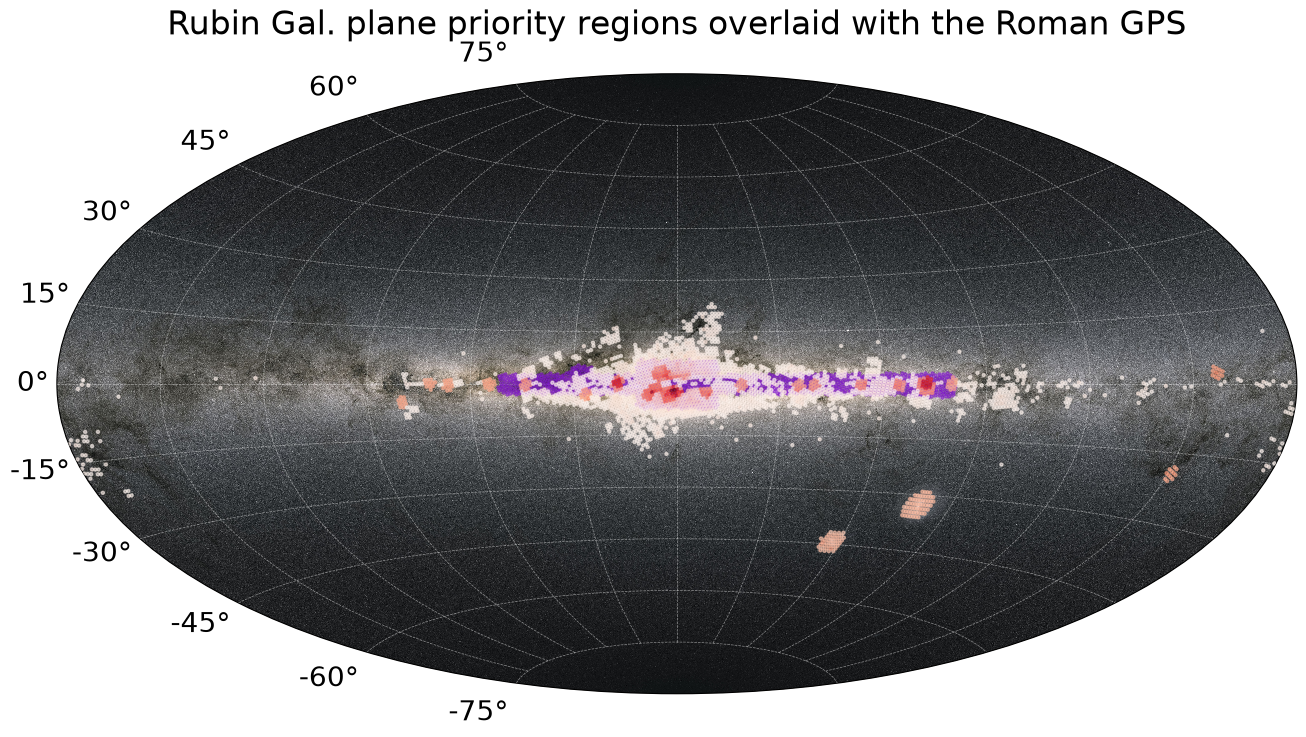

In [9]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Rubin Gal. plane priority regions overlaid with the Roman GPS'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot RGPS footprint
pixels = np.where(rgps_map_gal > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c='#8115CF', s=5, alpha=0.5)

# Plot Rubin footprint
pixels = np.where(selected_rubin_map > 0.08)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=selected_rubin_map[pixels], cmap='Reds', s=5, alpha=0.6)

## Nvisits as a function of footprint priority

The Galactic plane priority maps assign a priority per HEALpixel and the the Rubin MAF can be used to calculate the number of visits per HEALpixel.  By combining these, we can explore proportional reductions in the numbers of visits as a function of area.

First let's load the current baseline (v5.3) and calculate the number of visits per healpixel in order to get the footprint information.

In [10]:
opsdb = '/Users/rstreet/rubin_sim_data/sim_baseline/baseline_v5.3.0_10yrs.db'
runName = path.basename(opsdb).replace('.db','')
print(runName)

baseline_v5.3.0_10yrs


In [11]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)
outDir = '/Users/rstreet/LSST/SCOC/Survey_Footprint'

bundleList = []
metric1 = maf.metrics.CountMetric(col='observationStartMJD', metric_name='Nvisits')
constraint = 'fiveSigmaDepth > 21.5'
slicer = maf.slicers.HealpixSlicer(nside=NSIDE, use_cache=False)
plotDict = {'colorMax': 950}

bundle = maf.MetricBundle(metric1, slicer, constraint, run_name=runName, plot_dict=plotDict)
bgroup = maf.MetricBundleGroup({'nvisits': bundle}, opsdb, out_dir=outDir, results_db=None)

bgroup.run_all()

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes


In [12]:
# Number of visits per pixel
baseline_nvisits = bgroup.bundle_dict['nvisits'].metric_values.filled(0.0)

Using these arrays, we can plot the total number of visits included for a footprint generated with a given priority

In [13]:
priority_threshold = np.arange(combined_map.min(), combined_map.max(), 0.01)
survey_area = [PIXAREA*len(np.where(combined_map > threshold)[0]) for threshold in priority_threshold]
nvisits = [baseline_nvisits[np.where(combined_map > threshold)[0]].sum() for threshold in priority_threshold]
galplane_priority = [combined_map[np.where(combined_map > threshold)[0]] for threshold in priority_threshold]

In [14]:
# Index the pixels labeled 'bulgy' in the current Rubin footprint
_, rubin_pix_labels = get_current_footprint(nside=NSIDE)
gp_pixels = np.where(rubin_pix_labels == 'bulgy')[0]

current_survey_area = PIXAREA * len(gp_pixels)
print('Current Rubin Galactic plane footprint area = ' + str(current_survey_area) + 'sqdeg')
current_nvisits = baseline_nvisits[gp_pixels].sum()
print('Current total number of visits in the Rubin Galactic plane survey = ' + str(current_nvisits))

# Estimate a 10% reduction in the number of visits
reduce_fraction = 0.1
delta_visits = reduce_fraction*current_nvisits
reduced_nvisits = current_nvisits - delta_visits
print('So a reduction of ' + str(round(reduce_fraction*100,0)) 
      + '% in the number of visits is equivalent to ' + str(reduced_nvisits) + ' visits or ' 
      + str(delta_visits) + ' fewer visits')

Current Rubin Galactic plane footprint area = 1765.873829524295sqdeg
Current total number of visits in the Rubin Galactic plane survey = 1387444.0
So a reduction of 10.0% in the number of visits is equivalent to 1248699.6 visits or 138744.4 fewer visits


## Current footprint pixel priorities

Let's start from the current Galatic plane survey footprint, and include the priorities per included HEALpixel

In [15]:
current_gp_map = np.zeros(NPIX)
current_gp_map[gp_pixels] = combined_map[gp_pixels]

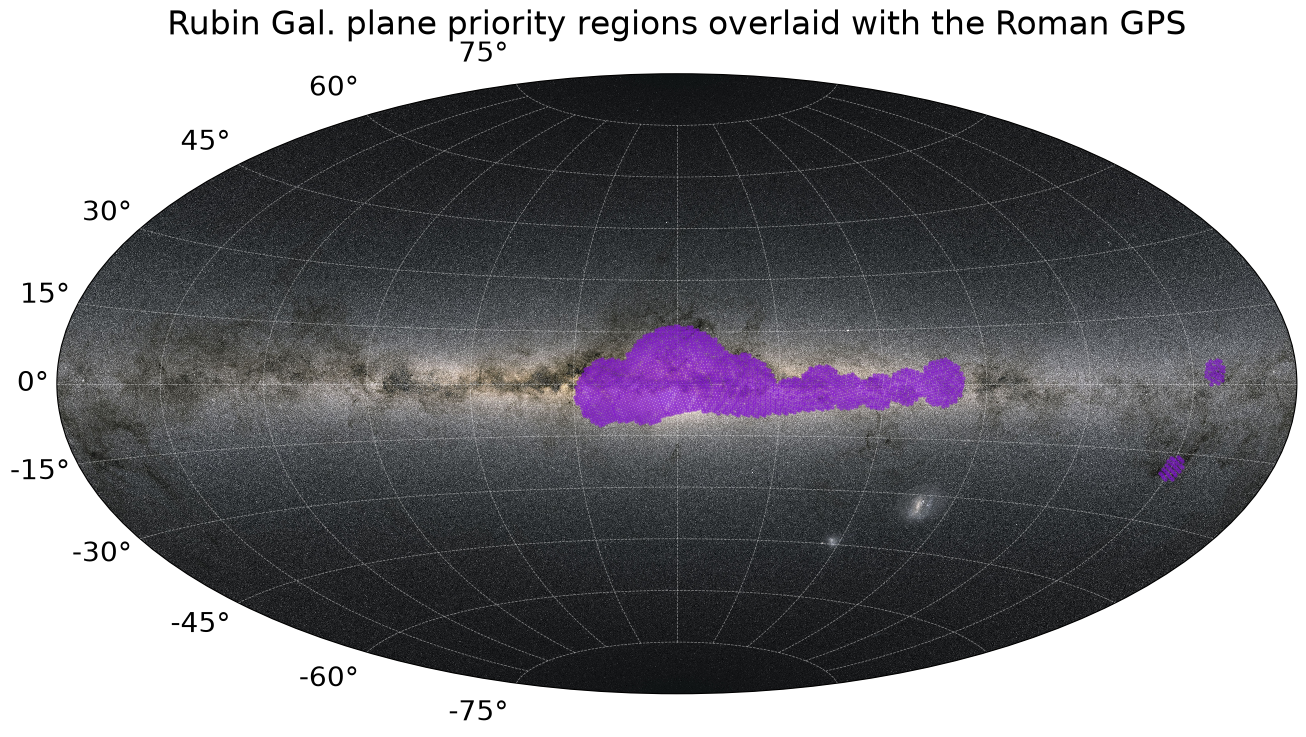

In [16]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Rubin Gal. plane priority regions overlaid with the Roman GPS'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

pixels = np.where(current_gp_map > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c='#8115CF', s=5, alpha=0.5)

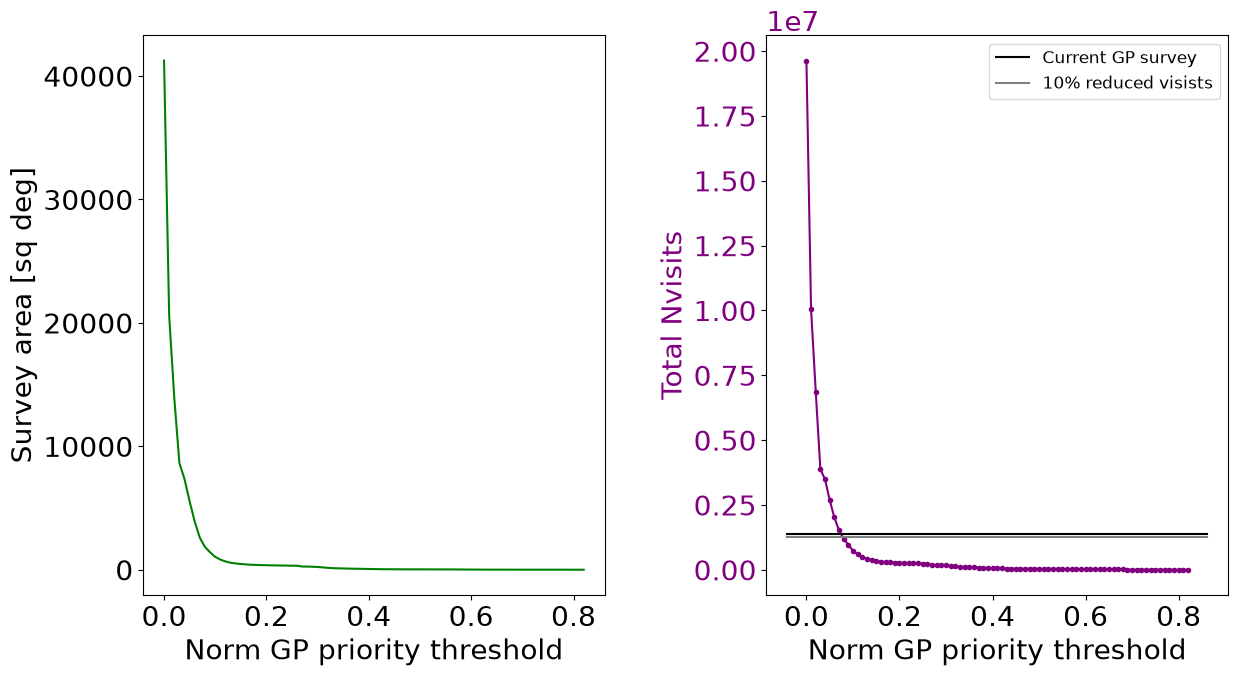

In [17]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(14,7))
plt.subplots_adjust(left=0.125, bottom=0.1, right=0.9, top=0.9, wspace=0.35, hspace=0.2)

ax1.plot(priority_threshold, survey_area, 'g-')

ax1.set_xlabel('Norm GP priority threshold')
ax1.set_ylabel('Survey area [sq deg]')

ax2.plot(priority_threshold, nvisits, color='purple', marker='.')
ax2.set_xlabel('Norm GP priority threshold')
ax2.set_ylabel('Total Nvisits', color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

(xmin, xmax) = ax2.get_xlim()

ax2.plot([xmin, xmax], [current_nvisits]*2, 'k-', label='Current GP survey')
ax2.plot([xmin, xmax], [reduced_nvisits]*2, color='grey', ls='-', label='10% reduced visists')

ax2.legend(fontsize=12)

Text(0, 0.5, 'Number of HEALpix with Nvisits')

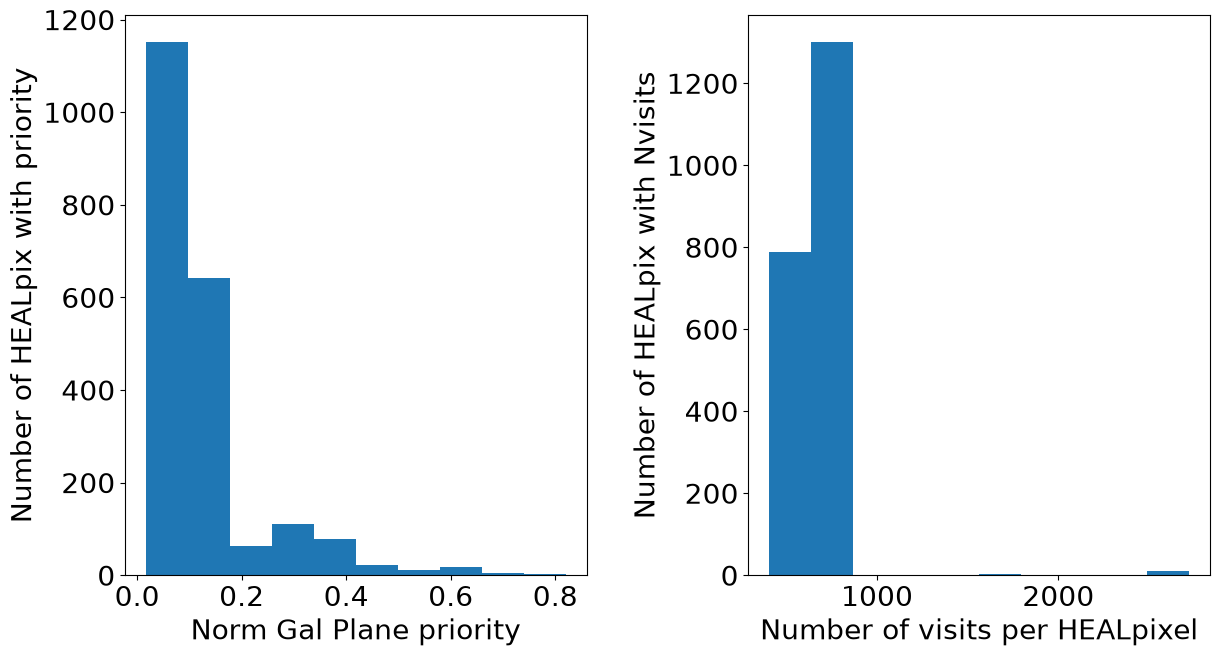

In [18]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(14,7))
plt.subplots_adjust(left=0.125, bottom=0.1, right=0.9, top=0.9, wspace=0.35, hspace=0.2)

pixels = np.where(current_gp_map > 0.0)[0]
ax1.hist(current_gp_map[pixels])
ax1.set_xlabel('Norm Gal Plane priority')
ax1.set_ylabel('Number of HEALpix with priority')

ax2.hist(baseline_nvisits[gp_pixels])
ax2.set_xlabel('Number of visits per HEALpixel')
ax2.set_ylabel('Number of HEALpix with Nvisits')


## Reduced Galactic plane footprint based on priority

Let's take the opposite approach.  What happens if we add HEALpixels to the map in order of priority, accumulating the visits per pixel (with no further changes made e.g. to filter balance) until we reach the maximum set by the reduction in the total visits. 

In [19]:
# Index all pixels in the Galactic plane map in order of highest priority first
pixel_order = np.argsort(current_gp_map)[::-1]

In [20]:
# Looping over all pixels in order of priority, sum the number of visits 
accumulated_visits = []
footprint_area = []
reduced_pixels = []
for pix in pixel_order:
    if pix in list(gp_pixels):
        accumulated_visits.append(baseline_nvisits[reduced_pixels].sum())
        footprint_area.append(PIXAREA * len(reduced_pixels))
        if accumulated_visits[-1] <= reduced_nvisits:
            reduced_pixels.append(pix)
            
print('Maximum reduced number of visits ('+str(reduced_nvisits)+') accumulated over ' + (str(len(reduced_pixels))) + ' pixels')
print('Compared with original number of pixels ' + str(len(gp_pixels)))
print('Equivalent to a total survey area of ' + str(PIXAREA * len(reduced_pixels)) + 'sqdeg')

Maximum reduced number of visits (1248699.6) accumulated over 1880 pixels
Compared with original number of pixels 2104
Equivalent to a total survey area of 1577.8720529969935sqdeg


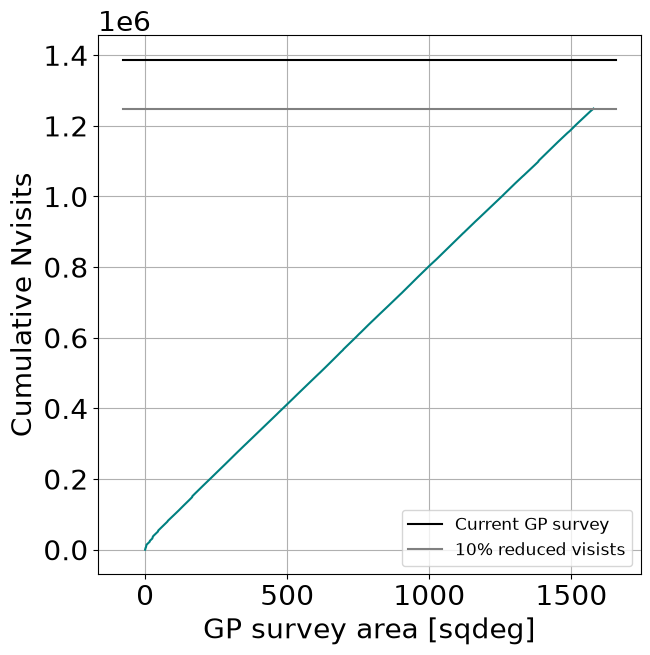

In [21]:
fig, ax = plt.subplots(1,1, figsize=(7,7))

ax.plot(footprint_area, accumulated_visits, color='teal', ls='-')

(xmin, xmax) = ax.get_xlim()

ax.plot([xmin, xmax], [current_nvisits]*2, 'k-', label='Current GP survey')
ax.plot([xmin, xmax], [reduced_nvisits]*2, color='grey', ls='-', label='10% reduced visists')

ax.set_xlabel('GP survey area [sqdeg]')
ax.set_ylabel('Cumulative Nvisits')

ax.legend(fontsize=12)
ax.grid()

So what does a Galactic plane survey with reduced_nvisits cover?

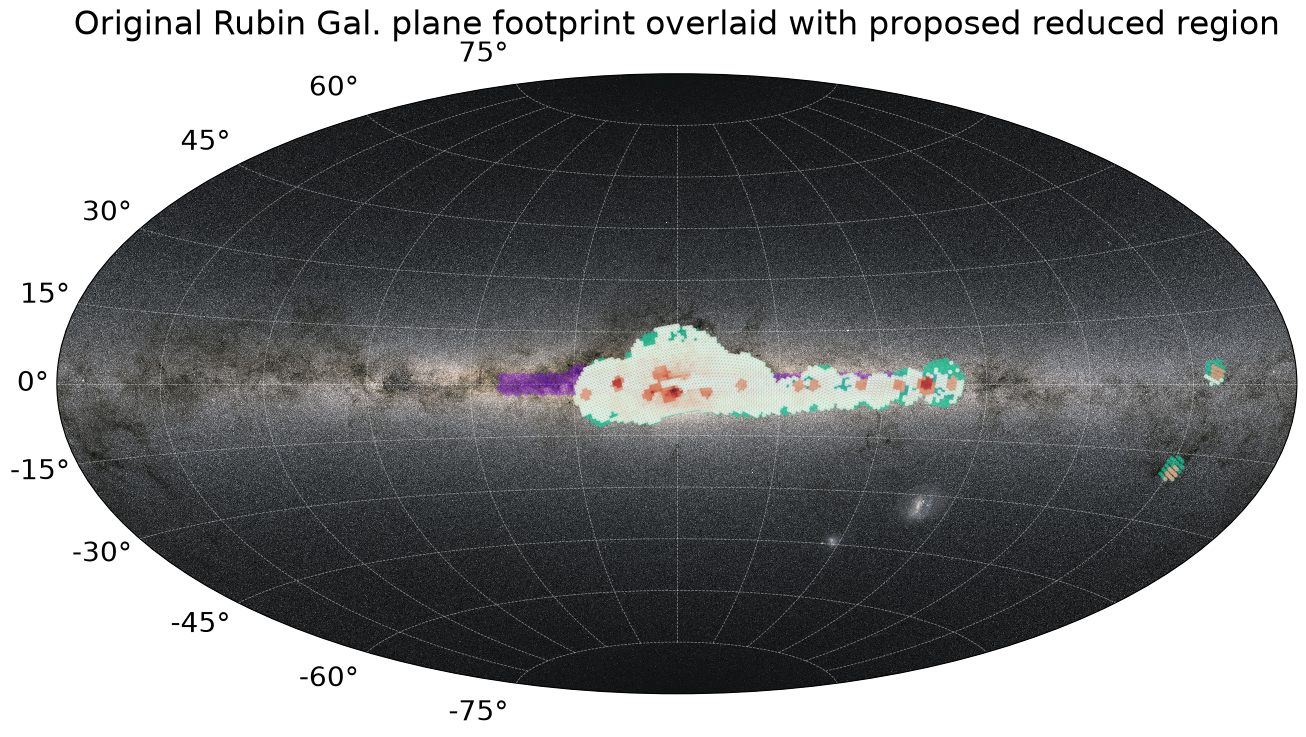

In [22]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Original Rubin Gal. plane footprint overlaid with proposed reduced region'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot RGPS footprint
pixels = np.where(rgps_map_gal > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c='#8115CF', s=5, alpha=0.3)

# Plot original Rubin Gal plane survey
pixels = np.where(current_gp_map > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c='#15CF9D', s=5, alpha=0.5)

# Plot Rubin footprint
s = proj.healpix_to_skycoord(reduced_pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=current_gp_map[reduced_pixels], cmap='Reds', s=5, alpha=0.6)

### Dark teal areas indicate HEALpixels removed from the proposed survey footprint

This approach removes some regions in the Northern bulge and to the extreme right-hand end of main footprint.  It still includes some coverage of the 'island' SFRs, and doesn't quite cover all of the visible Roman GPS. It also doesn't include an ecliptic bridge.  A more contiguous footprint is desirable for scheduler efficiency.  

So, a smoothed version of this footprint is preferred. 

The following process seeks to combine the Roman and reduced Rubin GP survey footprints as contiguously as possible.

In [37]:
# Ensure at all HEALpixels in the Roman footprint are included if are in the region that is not visible to Rubin
rgps_pixels = np.where(rgps_map_gal > 0.0)[0]
s = proj.healpix_to_skycoord(rgps_pixels)
s_gal = s.transform_to('galactic')

#30 < l < 60
idx1 = np.where(s_gal.l.deg < 60.0)[0]
idx2 = np.where(s_gal.l.deg > 30.0)[0]
idx = list(set(idx1).intersection(set(idx2)))
invisible_rgps_pixels = rgps_pixels[idx]

visible_rgps_pixels = [pix for pix in rgps_pixels if pix not in invisible_rgps_pixels]

In [38]:
# Ensure all visible RGPS pixels are included
revised_pixels = set(reduced_pixels)

revised_pixels = list(revised_pixels.union(visible_rgps_pixels))

In [39]:
# Remove islands at l~180-270deg
pixel_list = np.array([int(x) for x in revised_pixels])
s = proj.healpix_to_skycoord(pixel_list)
s_gal = s.transform_to('galactic')

idx1 = np.where(s_gal.l.deg > 180.0)[0]
idx2 = np.where(s_gal.l.deg < 270.0)[0]
idx = list(set(idx1).intersection(set(idx2)))
island_pixels = pixel_list[idx]

revised_pixels = [pix for pix in revised_pixels if pix not in island_pixels]


In [40]:
# Trim pixels b>12deg where the footprint becomes pixelated 
pixel_list = np.array([int(x) for x in revised_pixels])
s = proj.healpix_to_skycoord(pixel_list)
s_gal = s.transform_to('galactic')

idx = np.where(s_gal.b.deg < 13.0)[0]
revised_pixels = pixel_list[idx]


In [41]:
# Calculate the total area and numbers of visits if the observing strategy remains the same except for footprint 
new_survey_area = PIXAREA * len(revised_pixels)
print('Total area of revised survey footprint = ' + str(new_survey_area) + 'sqdeg')
nvisits = baseline_nvisits[revised_pixels].sum()
print('Total number of visits required for the revised footprint = ' + str(nvisits))
print('compare to the required reduced number of visits = ' + str(reduced_nvisits))

Total area of revised survey footprint = 1586.2649894491053sqdeg
Total number of visits required for the revised footprint = 1247786.0
compare to the required reduced number of visits = 1248699.6


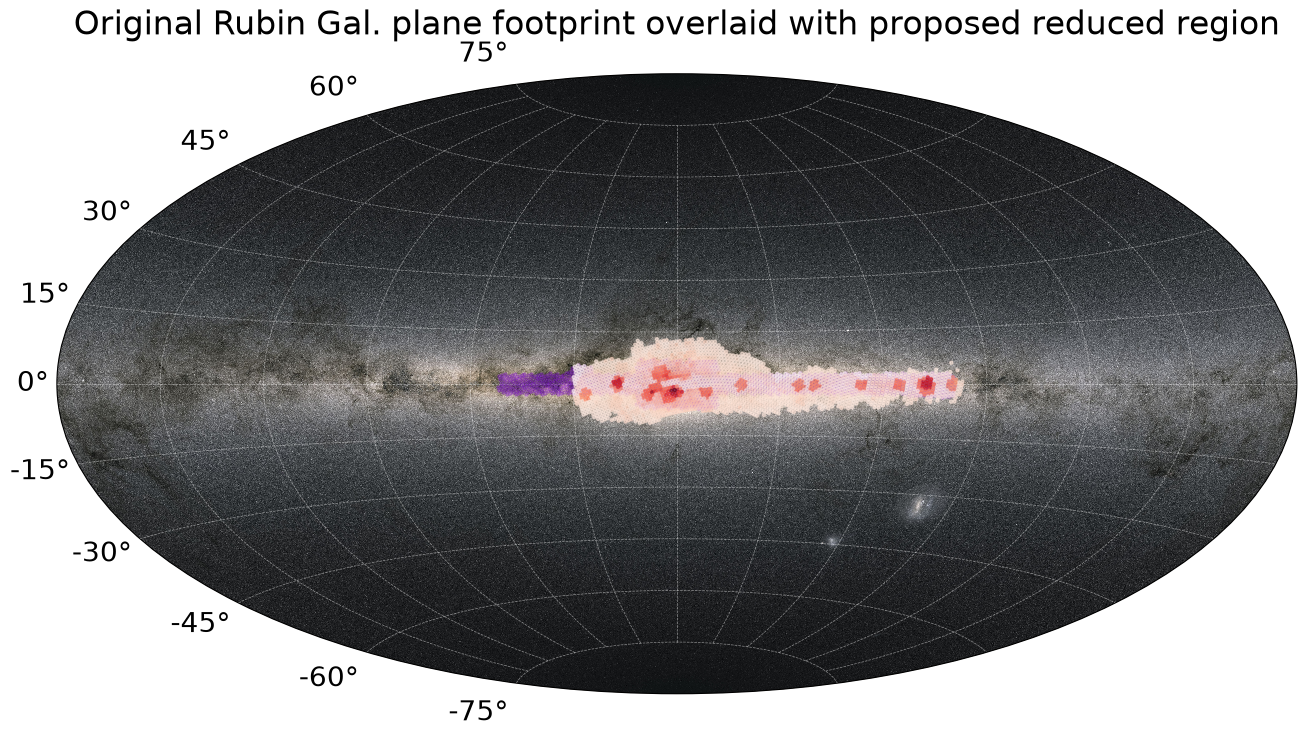

In [42]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Original Rubin Gal. plane footprint overlaid with proposed reduced region'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot RGPS footprint
pixels = np.where(rgps_map_gal > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c='#8115CF', s=5, alpha=0.3)

# Plot revised Rubin footprint
s = proj.healpix_to_skycoord(list(revised_pixels))
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=current_gp_map[list(revised_pixels)], cmap='Reds', s=5, alpha=0.6)

Let's output this as a HEALpixel list for reference:

In [43]:
json_string = json.dumps({'new_gp_pixels': revised_pixels.astype(int).tolist()})
file_path = path.join(home, 'software/LSST-TVSSC_software_tools/footprint_maps/new_rubin_gp_survey_footprint.json')
with open(file_path, 'w') as f:
    f.write(json_string)

This footprint is still somewhat pixelated and could be smoothed but it does have the advantage of covering some of the proposed ecliptic bridge already. 